# Kalp Hastalığı – Modelleme
**Veri akışı:** silver (temiz veri) → **gold** (modele hazır: kategorik değişkenler kodlanmış, eğitim/test ayrılmış) → modeller

In [9]:
import os, warnings
os.environ["PYTHONWARNINGS"] = "ignore"   # paralel çalışan işlemler için
warnings.filterwarnings("ignore")          # ana notebook için
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

sns.set_theme(style="whitegrid")
FIG = "../results/figures/"
TAB = "../results/tables/"
SEED = 42   # rastgeleliği sabitler, sonuçlar her çalıştırmada aynı çıkar

In [2]:
silver = pd.read_csv("../data/silver/heart_silver.csv")
print("Silver boyut:", silver.shape)
print("Eksik değerler:\n", silver.isna().sum()[silver.isna().sum() > 0])
silver.head()

Silver boyut: (917, 13)
Eksik değerler:
 Cholesterol    171
dtype: int64


,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease,Cholesterol_eksik
0,40,M,ATA,140,289.0,0,Normal,172,N,0.0,Up,0,0
1,49,F,NAP,160,180.0,0,Normal,156,N,1.0,Flat,1,0
2,37,M,ATA,130,283.0,0,ST,98,N,0.0,Up,0,0
3,48,F,ASY,138,214.0,0,Normal,108,Y,1.5,Flat,1,0
4,54,M,NAP,150,195.0,0,Normal,122,N,0.0,Up,0,0


In [3]:
KATEGORIK = ["Sex", "ChestPainType", "RestingECG", "ExerciseAngina", "ST_Slope"]
gold = pd.get_dummies(silver, columns=KATEGORIK, dtype=int)
print("Silver sütun sayısı:", silver.shape[1], "→ Gold sütun sayısı:", gold.shape[1])
gold.head()

Silver sütun sayısı: 13 → Gold sütun sayısı: 22


,Age,RestingBP,Cholesterol,FastingBS,MaxHR,Oldpeak,HeartDisease,Cholesterol_eksik,Sex_F,Sex_M,...,ChestPainType_NAP,ChestPainType_TA,RestingECG_LVH,RestingECG_Normal,RestingECG_ST,ExerciseAngina_N,ExerciseAngina_Y,ST_Slope_Down,ST_Slope_Flat,ST_Slope_Up
0,40,140,289.0,0,172,0.0,0,0,0,1,...,0,0,0,1,0,1,0,0,0,1
1,49,160,180.0,0,156,1.0,1,0,1,0,...,1,0,0,1,0,1,0,0,1,0
2,37,130,283.0,0,98,0.0,0,0,0,1,...,0,0,0,0,1,1,0,0,0,1
3,48,138,214.0,0,108,1.5,1,0,1,0,...,0,0,0,1,0,0,1,0,1,0
4,54,150,195.0,0,122,0.0,0,0,0,1,...,1,0,0,1,0,1,0,0,0,1


In [4]:
X = gold.drop(columns="HeartDisease")
y = gold["HeartDisease"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)

pd.concat([X_train, y_train], axis=1).to_csv("../data/gold/heart_train.csv", index=False)
pd.concat([X_test, y_test], axis=1).to_csv("../data/gold/heart_test.csv", index=False)

print("Eğitim:", X_train.shape, " Test:", X_test.shape)
print("Eğitimde hasta oranı: %.3f | Testte hasta oranı: %.3f" % (y_train.mean(), y_test.mean()))

Eğitim: (733, 21)  Test: (184, 21)
Eğitimde hasta oranı: 0.553 | Testte hasta oranı: 0.554


## Ön işleme pipeline'ı
Sayısal sütunlara iki adım uygulanır. İkisi de **sadece eğitim verisinden öğrenilir**, test verisine aynen uygulanır (veri sızıntısını önlemek için):
- **SimpleImputer (median):** Eksik kolesterol, eğitim verisinin medyanıyla doldurulur.
- **StandardScaler:** Değişkenler ortalaması 0, standart sapması 1 olacak şekilde ölçeklenir. KNN, SVM ve Lojistik Regresyon ölçeğe duyarlıdır.

In [5]:
SAYISAL = ["Age", "RestingBP", "Cholesterol", "MaxHR", "Oldpeak"]

onisleme = ColumnTransformer([
    ("sayisal", Pipeline([("doldur", SimpleImputer(strategy="median")),
                          ("olcekle", StandardScaler())]), SAYISAL),
], remainder="passthrough")   # diğer sütunlar (0/1 olanlar) olduğu gibi geçer

def model_kur(algoritma):
    return Pipeline([("onisleme", onisleme), ("model", algoritma)])

## Kullanılan algoritmalar
| Model | Nasıl çalışır? | Neden seçildi? |
|---|---|---|
| Lojistik Regresyon | Özelliklerin ağırlıklı toplamını olasılığa çevirir | Yorumlanabilir, tıpta temel model |
| KNN | Yeni hastayı en benzer k hastanın çoğunluğuna göre sınıflar | Basit, parametrik olmayan yöntem |
| SVM | İki sınıfı en geniş boşlukla ayıran sınırı bulur | Küçük-orta veri setlerinde güçlü |
| Karar Ağacı | Evet/hayır sorularıyla veriyi böler | Kurallarla açıklanabilir |
| Random Forest | Çok sayıda ağacın oylaması | Aşırı öğrenmeye dayanıklı |
| XGBoost | Ağaçları art arda, öncekinin hatasını düzelterek kurar | Tablo verilerinde en başarılı yöntemlerden |

In [6]:
modeller = {
    "Lojistik Regresyon": LogisticRegression(max_iter=1000, random_state=SEED),
    "KNN": KNeighborsClassifier(),
    "SVM": SVC(probability=True, random_state=SEED),
    "Karar Ağacı": DecisionTreeClassifier(random_state=SEED),
    "Random Forest": RandomForestClassifier(random_state=SEED),
    "XGBoost": XGBClassifier(random_state=SEED, eval_metric="logloss"),
}

def metrikler(model, X, y):
    tahmin = model.predict(X)
    olasilik = model.predict_proba(X)[:, 1]
    return {"Accuracy": accuracy_score(y, tahmin), "Precision": precision_score(y, tahmin),
            "Recall": recall_score(y, tahmin), "F1-Score": f1_score(y, tahmin),
            "ROC-AUC": roc_auc_score(y, olasilik)}

temel = {}
for ad, algoritma in modeller.items():
    m = model_kur(algoritma).fit(X_train, y_train)
    temel[ad] = metrikler(m, X_test, y_test)

temel_df = pd.DataFrame(temel).T.round(4).sort_values("ROC-AUC", ascending=False)
temel_df.to_csv(TAB + "kalp_temel_sonuclar.csv")
temel_df

/Users/semihnebitokalak/Desktop/MedBot/.venv/lib/python3.12/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


,Accuracy,Precision,Recall,F1-Score,ROC-AUC
SVM,0.8913,0.8727,0.9412,0.9057,0.9442
Random Forest,0.8696,0.8750,0.8922,0.8835,0.9356
Lojistik Regresyon,0.8804,0.8846,0.9020,0.8932,0.9354
KNN,0.8967,0.9029,0.9118,0.9073,0.9262
XGBoost,0.8478,0.8700,0.8529,0.8614,0.9132
Karar Ağacı,0.7717,0.7830,0.8137,0.7981,0.7666


## Hiperparametre optimizasyonu
**Hiperparametre:** Modelin veriden öğrenmediği, bizim önceden seçtiğimiz ayarlar (örn. KNN'de komşu sayısı, Random Forest'ta ağaç sayısı).

**GridSearchCV:** Verilen ayar kombinasyonlarının hepsini dener, en iyisini seçer.

**5 katlı çapraz doğrulama:** Eğitim verisi 5 parçaya bölünür. Model 4 parçayla eğitilip 1 parçayla test edilir, bu 5 kez tekrarlanır ve ortalama alınır. Ayarlar **test verisine hiç bakılmadan** seçilir. Seçim kriteri: ROC-AUC.

In [7]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold

izgaralar = {
    "Lojistik Regresyon": {"model__C": [0.01, 0.1, 1, 10],
                           "model__penalty": ["l1", "l2"],
                           "model__solver": ["liblinear"]},
    "KNN": {"model__n_neighbors": [3, 5, 7, 9, 11, 15, 21],
            "model__weights": ["uniform", "distance"],
            "model__p": [1, 2]},
    "SVM": {"model__C": [0.1, 1, 10],
            "model__kernel": ["linear", "rbf"],
            "model__gamma": ["scale", 0.01, 0.1]},
    "Karar Ağacı": {"model__max_depth": [3, 4, 5, 6, 8, None],
                    "model__min_samples_leaf": [1, 5, 10, 20],
                    "model__criterion": ["gini", "entropy"]},
    "Random Forest": {"model__n_estimators": [200, 500],
                      "model__max_depth": [None, 5, 10],
                      "model__min_samples_leaf": [1, 3, 5],
                      "model__max_features": ["sqrt", 0.5]},
    "XGBoost": {"model__n_estimators": [100, 300],
                "model__max_depth": [2, 3, 5],
                "model__learning_rate": [0.01, 0.05, 0.1],
                "model__subsample": [0.8, 1.0]},
}

In [10]:
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

en_iyi_modeller, secilen = {}, []
for ad, algoritma in modeller.items():
    arama = GridSearchCV(model_kur(algoritma), izgaralar[ad], scoring="roc_auc", cv=cv5, n_jobs=-1)
    arama.fit(X_train, y_train)
    en_iyi_modeller[ad] = arama.best_estimator_
    parametreler = {k.replace("model__", ""): v for k, v in arama.best_params_.items()}
    secilen.append({"Model": ad, "Seçilen hiperparametreler": parametreler,
                    "CV ROC-AUC": round(arama.best_score_, 4)})
    print(f"{ad:20s} CV ROC-AUC = {arama.best_score_:.4f}  {parametreler}")

pd.DataFrame(secilen).to_csv(TAB + "kalp_secilen_hiperparametreler.csv", index=False)

Lojistik Regresyon   CV ROC-AUC = 0.9258  {'C': 1, 'penalty': 'l1', 'solver': 'liblinear'}
KNN                  CV ROC-AUC = 0.9245  {'n_neighbors': 21, 'p': 1, 'weights': 'distance'}
SVM                  CV ROC-AUC = 0.9266  {'C': 10, 'gamma': 'scale', 'kernel': 'linear'}
Karar Ağacı          CV ROC-AUC = 0.9084  {'criterion': 'entropy', 'max_depth': 4, 'min_samples_leaf': 20}
Random Forest        CV ROC-AUC = 0.9348  {'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 3, 'n_estimators': 200}
XGBoost              CV ROC-AUC = 0.9369  {'learning_rate': 0.05, 'max_depth': 3, 'n_estimators': 100, 'subsample': 1.0}


In [11]:
opt = {ad: metrikler(m, X_test, y_test) for ad, m in en_iyi_modeller.items()}
opt_df = pd.DataFrame(opt).T.round(4).sort_values("ROC-AUC", ascending=False)
opt_df.to_csv(TAB + "kalp_optimize_sonuclar.csv")

karsilastirma = pd.DataFrame({
    "ROC-AUC (varsayılan)": temel_df["ROC-AUC"],
    "ROC-AUC (optimize)": opt_df["ROC-AUC"],
    "F1 (varsayılan)": temel_df["F1-Score"],
    "F1 (optimize)": opt_df["F1-Score"],
}).loc[opt_df.index]
karsilastirma["ROC-AUC farkı"] = (karsilastirma["ROC-AUC (optimize)"] - karsilastirma["ROC-AUC (varsayılan)"]).round(4)
karsilastirma.to_csv(TAB + "kalp_optimizasyon_etkisi.csv")

display(opt_df)
display(karsilastirma)

,Accuracy,Precision,Recall,F1-Score,ROC-AUC
SVM,0.8641,0.8532,0.9118,0.8815,0.9363
KNN,0.9022,0.9286,0.8922,0.9100,0.9349
Random Forest,0.8804,0.8774,0.9118,0.8942,0.9332
Lojistik Regresyon,0.8859,0.8857,0.9118,0.8986,0.9330
XGBoost,0.8913,0.8942,0.9118,0.9029,0.9280
Karar Ağacı,0.8424,0.8476,0.8725,0.8599,0.8832


,ROC-AUC (varsayılan),ROC-AUC (optimize),F1 (varsayılan),F1 (optimize),ROC-AUC farkı
SVM,0.9442,0.9363,0.9057,0.8815,-0.0079
KNN,0.9262,0.9349,0.9073,0.9100,0.0087
Random Forest,0.9356,0.9332,0.8835,0.8942,-0.0024
Lojistik Regresyon,0.9354,0.9330,0.8932,0.8986,-0.0024
XGBoost,0.9132,0.9280,0.8614,0.9029,0.0148
Karar Ağacı,0.7666,0.8832,0.7981,0.8599,0.1166


## Tekrarlı çapraz doğrulama
Test kümesi sadece 184 hastadan oluşuyor; tek bölmenin sonucu şansa bağlı olabilir. Seçilen ayarlarla tüm veri üzerinde **10 katlı × 5 tekrarlı** çapraz doğrulama yapılır (50 farklı test). Sonuçlar ortalama ± standart sapma olarak verilir.

In [12]:
from sklearn.model_selection import RepeatedStratifiedKFold, cross_validate

rcv = RepeatedStratifiedKFold(n_splits=10, n_repeats=5, random_state=SEED)
skorlar = {"Accuracy": "accuracy", "Precision": "precision", "Recall": "recall",
           "F1-Score": "f1", "ROC-AUC": "roc_auc"}

cv_tablo, cv_auc = {}, {}
for ad, m in en_iyi_modeller.items():
    sonuc = cross_validate(m, X, y, cv=rcv, scoring=skorlar, n_jobs=-1)
    cv_auc[ad] = sonuc["test_ROC-AUC"]
    cv_tablo[ad] = {k: f"{sonuc['test_' + k].mean():.3f} ± {sonuc['test_' + k].std():.3f}" for k in skorlar}

cv_df = pd.DataFrame(cv_tablo).T.loc[opt_df.index]
cv_df.to_csv(TAB + "kalp_tekrarli_cv.csv")
cv_df

,Accuracy,Precision,Recall,F1-Score,ROC-AUC
SVM,0.869 ± 0.032,0.866 ± 0.041,0.905 ± 0.033,0.884 ± 0.027,0.929 ± 0.024
KNN,0.873 ± 0.033,0.872 ± 0.042,0.905 ± 0.035,0.887 ± 0.028,0.927 ± 0.030
Random Forest,0.878 ± 0.030,0.867 ± 0.040,0.923 ± 0.028,0.893 ± 0.025,0.932 ± 0.028
Lojistik Regresyon,0.872 ± 0.033,0.872 ± 0.042,0.903 ± 0.034,0.886 ± 0.027,0.929 ± 0.024
XGBoost,0.878 ± 0.028,0.876 ± 0.038,0.910 ± 0.031,0.892 ± 0.024,0.936 ± 0.023
Karar Ağacı,0.836 ± 0.034,0.837 ± 0.039,0.877 ± 0.041,0.856 ± 0.029,0.903 ± 0.035


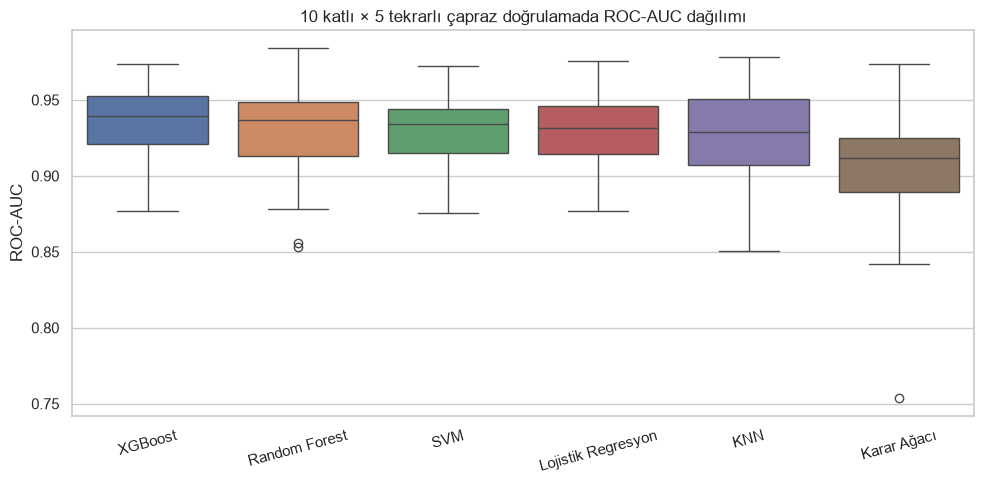

In [13]:
sirali = sorted(cv_auc, key=lambda a: -cv_auc[a].mean())
plt.figure(figsize=(10, 5))
sns.boxplot(data=[cv_auc[a] for a in sirali])
plt.xticks(range(len(sirali)), sirali, rotation=15)
plt.ylabel("ROC-AUC"); plt.title("10 katlı × 5 tekrarlı çapraz doğrulamada ROC-AUC dağılımı")
plt.tight_layout(); plt.savefig(FIG + "kalp_06_cv_kutu.png", dpi=150); plt.show()

## Final modelin seçimi ve değerlendirme
Seçim kriteri: tekrarlı çapraz doğrulamadaki ortalama ROC-AUC (tek test bölmesinden daha güvenilir).

In [14]:
final_ad = max(cv_auc, key=lambda a: cv_auc[a].mean())
final_model = en_iyi_modeller[final_ad]
print(f"Seçilen model: {final_ad}  (CV ROC-AUC = {cv_auc[final_ad].mean():.3f} ± {cv_auc[final_ad].std():.3f})")

Seçilen model: XGBoost  (CV ROC-AUC = 0.936 ± 0.023)


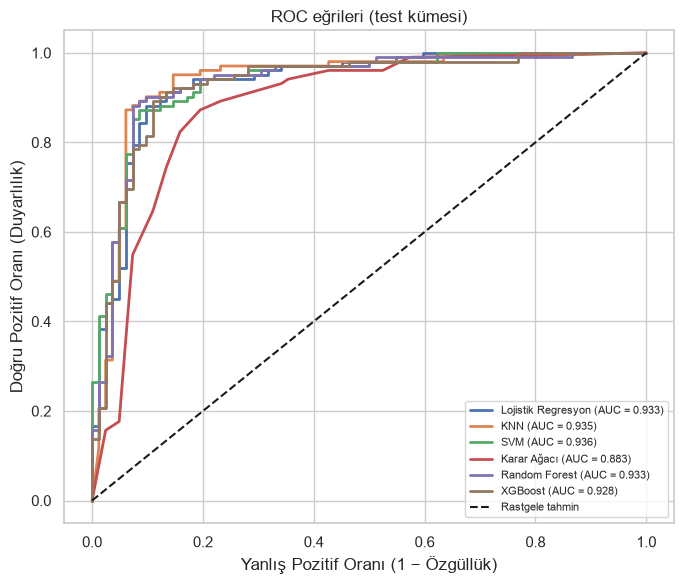

In [15]:
from sklearn.metrics import roc_curve

plt.figure(figsize=(7, 6))
for ad, m in en_iyi_modeller.items():
    olasilik = m.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, olasilik)
    plt.plot(fpr, tpr, lw=2, label=f"{ad} (AUC = {roc_auc_score(y_test, olasilik):.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Rastgele tahmin")
plt.xlabel("Yanlış Pozitif Oranı (1 − Özgüllük)")
plt.ylabel("Doğru Pozitif Oranı (Duyarlılık)")
plt.title("ROC eğrileri (test kümesi)"); plt.legend(loc="lower right", fontsize=8)
plt.tight_layout(); plt.savefig(FIG + "kalp_07_roc_egrileri.png", dpi=150); plt.show()

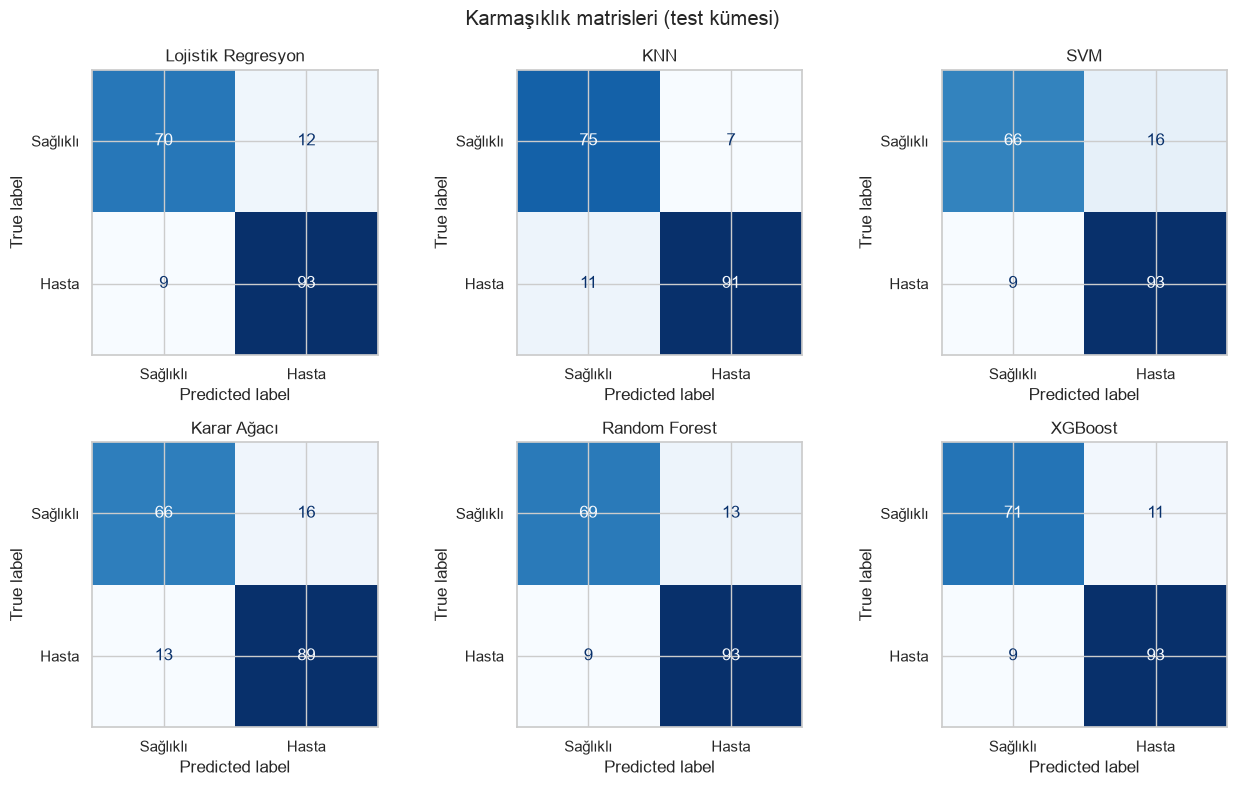

In [16]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

fig, axes = plt.subplots(2, 3, figsize=(13, 8))
for ax, (ad, m) in zip(axes.flat, en_iyi_modeller.items()):
    ConfusionMatrixDisplay(confusion_matrix(y_test, m.predict(X_test)),
                           display_labels=["Sağlıklı", "Hasta"]).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(ad)
plt.suptitle("Karmaşıklık matrisleri (test kümesi)")
plt.tight_layout(); plt.savefig(FIG + "kalp_08_karmasiklik_matrisleri.png", dpi=150); plt.show()

In [17]:
from scipy.stats import wilcoxon

anlamlilik = []
for ad in cv_auc:
    if ad == final_ad:
        continue
    p = wilcoxon(cv_auc[final_ad], cv_auc[ad]).pvalue
    anlamlilik.append({"Karşılaştırma": f"{final_ad} vs {ad}",
                       "Ortalama fark": round(cv_auc[final_ad].mean() - cv_auc[ad].mean(), 4),
                       "p-değeri": round(p, 4),
                       "Anlamlı mı? (p < 0.05)": "Evet" if p < 0.05 else "Hayır"})
anlamlilik_df = pd.DataFrame(anlamlilik)
anlamlilik_df.to_csv(TAB + "kalp_istatistiksel_test.csv", index=False)
anlamlilik_df

,Karşılaştırma,Ortalama fark,p-değeri,Anlamlı mı? (p < 0.05)
0,XGBoost vs Lojistik Regresyon,0.0071,0.0000,Evet
1,XGBoost vs KNN,0.0087,0.0003,Evet
2,XGBoost vs SVM,0.0065,0.0001,Evet
3,XGBoost vs Karar Ağacı,0.0328,0.0000,Evet
4,XGBoost vs Random Forest,0.0042,0.0156,Evet


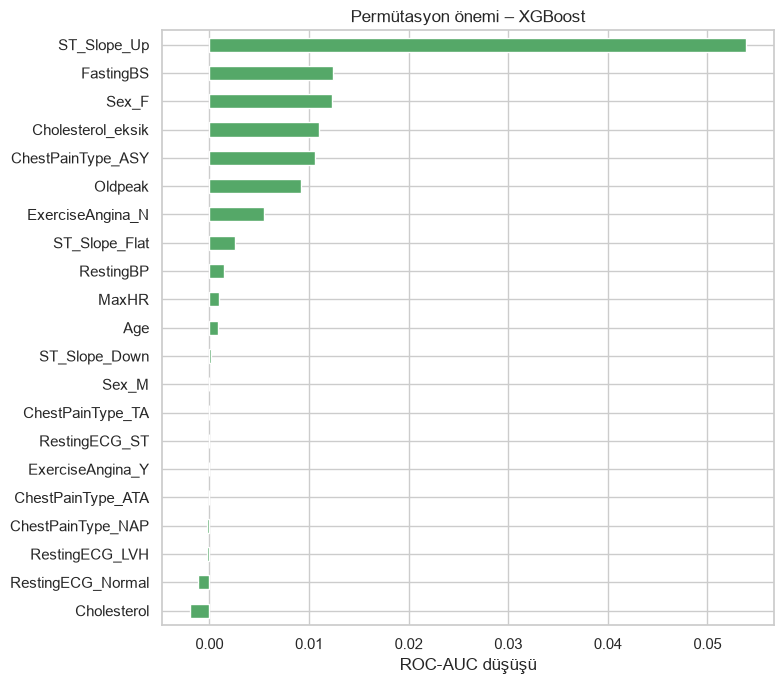

In [18]:
from sklearn.inspection import permutation_importance

pi = permutation_importance(final_model, X_test, y_test, scoring="roc_auc", n_repeats=30, random_state=SEED, n_jobs=-1)
onem = pd.Series(pi.importances_mean, index=X_test.columns).sort_values()
onem.to_csv(TAB + "kalp_ozellik_onemi.csv")

plt.figure(figsize=(8, 7))
onem.plot(kind="barh", color="#55A868")
plt.title(f"Permütasyon önemi – {final_ad}"); plt.xlabel("ROC-AUC düşüşü")
plt.tight_layout(); plt.savefig(FIG + "kalp_09_ozellik_onemi.png", dpi=150); plt.show()

## Modelin kaydedilmesi
Final model, tüm veriyle (eğitim + test) yeniden eğitilip chatbotta kullanılmak üzere `models/` klasörüne kaydedilir. Sütun listesi de saklanır; chatbot kullanıcıdan aldığı cevapları bu sütunlara göre hazırlayacak.

In [19]:
import joblib
from sklearn.base import clone

final_tum_veri = clone(final_model).fit(X, y)
joblib.dump({"model": final_tum_veri,
             "model_adi": final_ad,
             "sutunlar": list(X.columns)},
            "../models/kalp_modeli.pkl")
print(f"Kaydedildi: models/kalp_modeli.pkl  ({final_ad})")

Kaydedildi: models/kalp_modeli.pkl  (XGBoost)
